# Estimating Amazon's Market Beta with Python

This notebook downloads 15 years of monthly price data for **Amazon (AMZN)** and the **S&P 500 ETF (SPY)**, calculates monthly returns, visualizes performance and volatility, and runs an **OLS regression** to estimate Amazon's beta, a core measure of market risk used in the CAPM and cost-of-equity calculations.

**Tools:** Python, pandas, yfinance, matplotlib, statsmodels

**Steps**
1. Download monthly adjusted prices from Yahoo Finance
2. Combine the two series and compute monthly returns
3. Plot returns, growth of $100, return distribution, and a scatterplot
4. Run an OLS regression of AMZN returns on SPY returns to estimate beta

### Step 1: Download data

In [ ]:
!pip install yfinance statsmodels -q
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [ ]:
# Download monthly adjusted close prices for Amazon and the S&P 500 ETF (Jan 2011 - Nov 2025)
mystock = yf.download("AMZN", start="2011-01-01", end="2025-11-17", interval='1mo', auto_adjust=False)['Adj Close']
mystock.name = 'AMZN' # Rename the series by assigning to the name attribute
index = yf.download("SPY", start="2011-01-01", end="2025-11-17", interval='1mo', auto_adjust=False)['Adj Close']
index.name = 'SPY' # Rename the series by assigning to the name attribute

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


### Step 2: Combine the series and compute monthly returns

In [ ]:
# combine two asset prices into one matrix
data = pd.concat([mystock, index], axis=1)

# drop missing observations
data2 = data.dropna()

# compute monthly returns from the prices and drop the first observation
data3 = data2.pct_change().dropna()
data3

Ticker,AMZN,SPY
Date,,
2011-02-01,0.021516,0.034737
2011-03-01,0.039471,-0.004206
2011-04-01,0.087048,0.033431
2011-05-01,0.004494,-0.011214
2011-06-01,0.039656,-0.021720
...,...,...
2025-07-01,0.067095,0.026056
2025-08-01,-0.021827,0.020520
2025-09-01,-0.041179,0.032757


### Step 3: Visualize the data

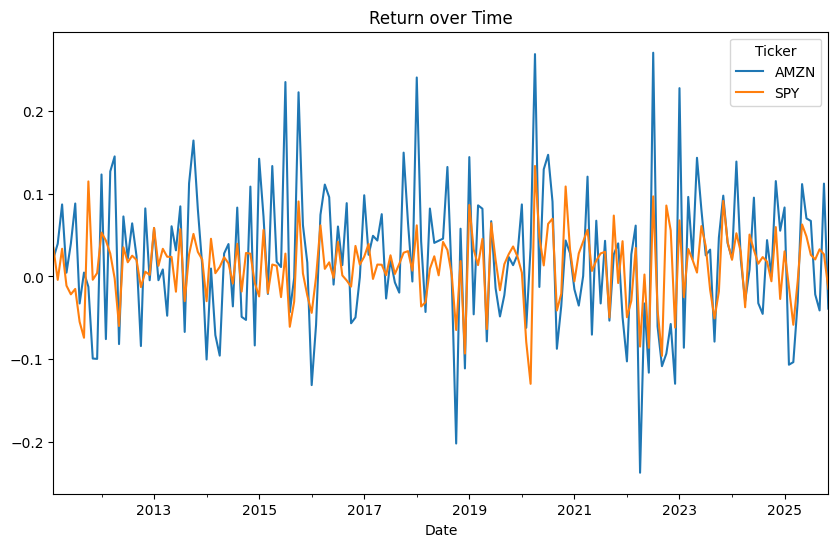

In [ ]:
import matplotlib.pyplot as plt                                            # imports the matplotlib library.

data3.plot(subplots=False, figsize=(10, 6))                                # plots returns in a chart to see volatility levels.

plt.title('Return over Time')                                              # places the title of the graph
plt.show()


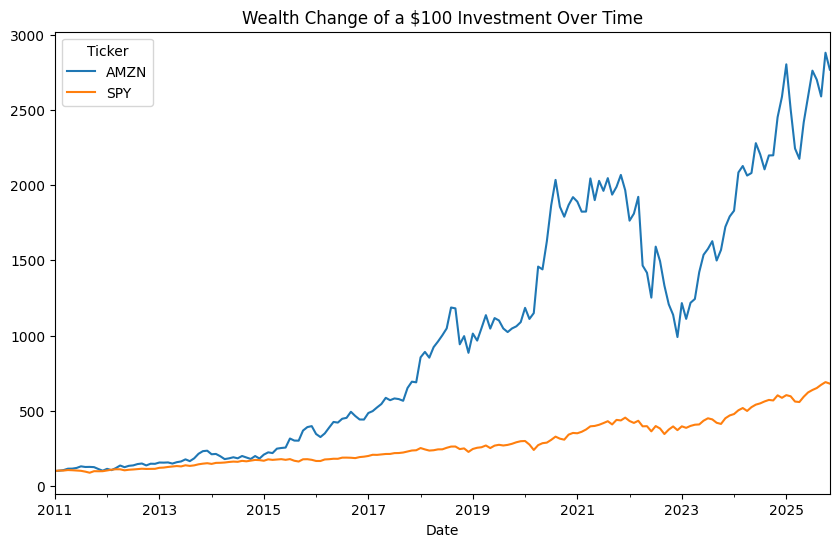

In [ ]:
(data2 / data2.iloc[0] * 100).plot(figsize = (10, 6), subplots=False)                     # plots the wealth change of $100 investment over time.
plt.title('Wealth Change of a $100 Investment Over Time')                                 # places the title of the graph
plt.show()

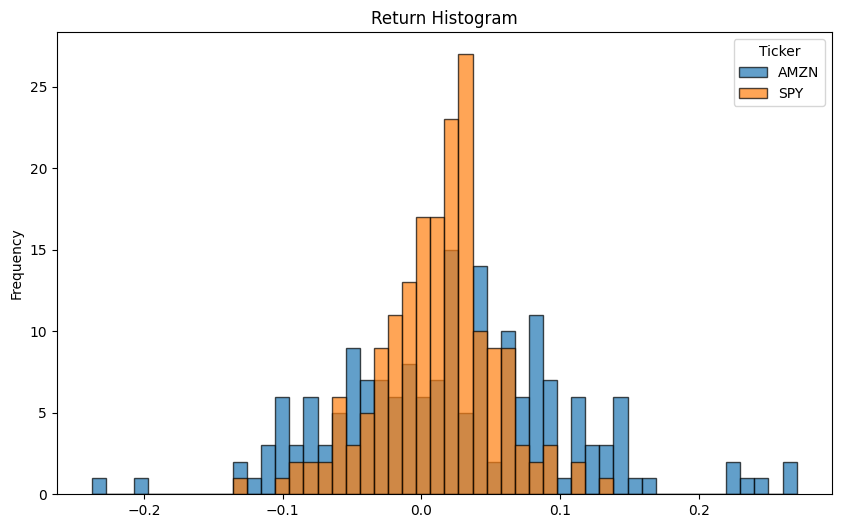

In [ ]:
data3.plot.hist(bins=50, alpha=0.7, edgecolor='black', subplots=False, figsize=(10,6))    # plots a histogram of the returns
plt.title('Return Histogram')                                                             # places the title of the graph
plt.show()

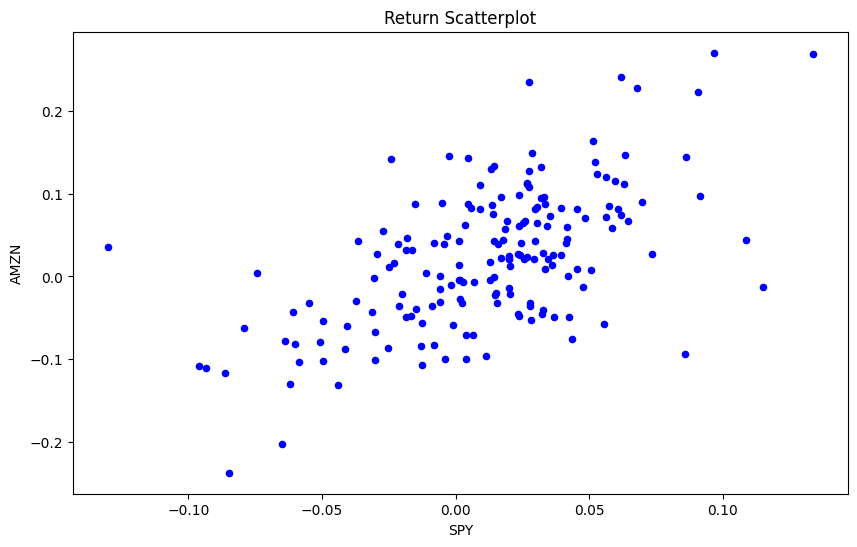

In [ ]:
data3.plot.scatter(x='SPY', y='AMZN', c='blue',figsize=(10,6))                            # plots a scatterplot of the returns
plt.title('Return Scatterplot')                                                           # places the title of the graph
plt.show()

### Step 4: Run the OLS regression to estimate beta

In [ ]:
# now run OLS, i.e. the regression
formula = 'AMZN ~ SPY'                      # set dep var and indep var
results = smf.ols(formula, data3).fit()     # runs OLS
print(results.summary())                    # prints regression output

                            OLS Regression Results                            
Dep. Variable:                   AMZN   R-squared:                       0.349
Model:                            OLS   Adj. R-squared:                  0.345
Method:                 Least Squares   F-statistic:                     94.22
Date:                Mon, 17 Nov 2025   Prob (F-statistic):           4.14e-18
Time:                        19:28:07   Log-Likelihood:                 226.34
No. Observations:                 178   AIC:                            -448.7
Df Residuals:                     176   BIC:                            -442.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0083      0.005      1.561      0.1

## Results and interpretation

| Metric | Value |
|---|---|
| Beta (AMZN vs. SPY) | **1.196** |
| 95% confidence interval | 0.953 to 1.439 |
| R-squared | 0.349 |
| Observations | 178 monthly returns (Feb 2011 to Nov 2025) |
| Beta p-value | < 0.001 |

- **Amazon is more volatile than the market.** A beta of about 1.2 means that, on average, when the S&P 500 moves 1%, Amazon tends to move about 1.2% in the same direction.
- **The estimate is statistically significant.** The confidence interval sits entirely around or above 1, so Amazon's market sensitivity is reliably near or above the market's.
- **The market explains about 35% of Amazon's monthly return variation.** The rest comes from company-specific factors like earnings, AWS growth, and news.
- **Why it matters:** Beta feeds into the CAPM to estimate a company's cost of equity, which is used in valuation and investment decisions.